# *MAPT* Analysis

In [1]:
# python v3.14.7

#dependencies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from collections import Counter

### File Setup
Use `pandas` to establish data frame from VEP result tsv file
- Data frames + `pandas` is much easier to navigate than a regular tsv

In [2]:
# import tsv as dataframe (df)
df = pd.read_csv('2026-11-16-22-21_VEP_filtered_MAPT.tsv', sep='\t')
df.convert_dtypes()
# print(df)

/var/folders/dc/s582b67d4hv6c8vxps5mm89c0000gn/T/ipykernel_2252/1124268627.py:2: DtypeWarning: Columns (12: INTRON, 14: HGVSp, 15: cDNA_position, 16: CDS_position, 17: Protein_position, 18: Amino_acids, 19: Codons, 56: EVE_CLASS, 62: popEVE_gene, 63: popEVE_mutant, 66: popEVE_protein, 67: ProtVar_int, 68: ProtVar_pocket, 71: am_class, 80: SpliceAI_pred_DP_DL, 96: gnomAD_genomes_AF_grpmax, 114: ClinVar_CLNSIGCONF, 126: ClinVar_CLNPMID, 134: GENCODE_Promoter, 135: GENCODE_Promoter_type, 136: GENCODE_Promoter_feature_id, 137: GENCODE_Promoter_associated_gene) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('2026-11-16-22-21_VEP_filtered_MAPT.tsv', sep='\t')


,Uploaded_variation,Location,Ref,Allele,Consequence,IMPACT,SYMBOL,Gene,Feature_type,Feature,...,ClinVar_SCI,ClinVar_SCIREVSTAT,ClinVar_SCIDN,ClinVar_SCIDISDB,ClinVar_GENEINFO,GENCODE_Promoter,GENCODE_Promoter_type,GENCODE_Promoter_feature_id,GENCODE_Promoter_associated_gene,genes.gff3.bgz
0,rs886053021,17:45894389,C,A,upstream_gene_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00000262410.10,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137&MAPT-AS1:100128977,17:45893554-45894553,promoter_window,ENSG00000186868_promoter_window,ENSG00000186868.19,<NA>
1,rs886053021,17:45894389,C,A,5_prime_UTR_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00000334239.13,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137&MAPT-AS1:100128977,17:45893554-45894553,promoter_window,ENSG00000186868_promoter_window,ENSG00000186868.19,<NA>
2,rs886053021,17:45894389,C,A,5_prime_UTR_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00000344290.11,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137&MAPT-AS1:100128977,17:45893554-45894553,promoter_window,ENSG00000186868_promoter_window,ENSG00000186868.19,<NA>
3,rs886053021,17:45894389,C,A,5_prime_UTR_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00000351559.11,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137&MAPT-AS1:100128977,17:45893554-45894553,promoter_window,ENSG00000186868_promoter_window,ENSG00000186868.19,<NA>
4,rs886053021,17:45894389,C,A,5_prime_UTR_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00000420682.8,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137&MAPT-AS1:100128977,17:45893554-45894553,promoter_window,ENSG00000186868_promoter_window,ENSG00000186868.19,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13360,rs1267052993,17:46028242,G,A,3_prime_UTR_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00000972118.2,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137,<NA>,<NA>,<NA>,<NA>,<NA>
13361,rs1267052993,17:46028242,G,A,3_prime_UTR_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00000972119.2,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137,<NA>,<NA>,<NA>,<NA>,<NA>
13362,rs1267052993,17:46028242,G,A,3_prime_UTR_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00000972120.2,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137,<NA>,<NA>,<NA>,<NA>,<NA>
13363,rs1267052993,17:46028242,G,A,downstream_gene_variant,MODIFIER,MAPT,ENSG00000186868.20,Transcript,ENST00001043074.1,...,<NA>,<NA>,<NA>,<NA>,MAPT:4137,<NA>,<NA>,<NA>,<NA>,<NA>


### 1. Comparing ClinVar Significance classification to Position

(a) Using original df, gather columns of interest using `.iloc[]` from `pandas` package to extract columns based on position

- Then, extract rows based on criteria of matching exactly index value
- Assign each extracted row to its own data frame

(b) Convert extracted data frames to list of tuples

- Conversion to tuples make later use for plotting easier
- Replace ClinVar_CLNSIG or ClinVar_CLNSIGCONF with float between -7 and 7 for stem height


(c) Create Stem Plot (matplotlib)

- x-axis = chromosomal position
- y-axis = ClinVar significance classification
- y-height: taller -> Stronger evidence
- Color map: red -> pathogenic | blue -> uncertain | green -> benign

(d) Create Stem Plot with Jitter

- Adding jitter to x-values makes separate stems more easily distinguished

In [3]:
# COMPARING CLINVAR SIGNIFICANCE to POSITION
# (1.a) Set up data frames for each of the ClnSig tracks, separately

# extract location, ClinVar_CLNSIG, and ClinVar_CLNSIGCONF
cln_sig = df.iloc[:,[1, 113, 114]]

# fill missing data with N/A placeholder, and remove 17: prefix to location
cln_sig=cln_sig.fillna('N/A').replace(r'17:','', regex=True)

# establish value counts for reference
cln_sig_counts=cln_sig.value_counts()

# create subset data frames based on values in ClinVar_CLNSIG
    # [!] values will be assigned to color (value = cmap range)
df_path=cln_sig[cln_sig.ClinVar_CLNSIG == 'Pathogenic'] # value = 7
df_path_likely=cln_sig[cln_sig.ClinVar_CLNSIG == 'Pathogenic/Likely_pathogenic'] # value = 5
df_likely_path=cln_sig[cln_sig.ClinVar_CLNSIG == 'Likely_pathogenic'] # value = 3
df_uncertain= cln_sig[cln_sig.ClinVar_CLNSIG == 'Uncertain_significance'] # value = 0
df_likely_ben = cln_sig[cln_sig.ClinVar_CLNSIG == 'Likely_benign'] # value = -3
df_ben_likely = cln_sig[cln_sig.ClinVar_CLNSIG == 'Benign/Likely_benign'] # value = -5
df_ben=cln_sig[cln_sig.ClinVar_CLNSIG == 'Benign'] # value = -7

# create subset data frames for subset (OR) for not_provided + N/A
df_not_provided = cln_sig[(cln_sig.ClinVar_CLNSIG == 'not_provided') | (cln_sig.ClinVar_CLNSIG == 'N/A')]

# create subset data frames based on values in ClinVar_CLNSIGCONF
    # all containing benign/likely benign
df_con_ben = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(1)+Benign_(1)'] # value = -4
df_con_ben3 = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(1)+Benign_(3)'] # value = -6.5
df_con2_ben = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(2)+Benign_(1)'] # value = -2
df_con_ben_likely = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(2)+Likely_benign_(1)'] # value = -0.75
df_con2_ben_likely = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(1)+Likely_benign_(1)'] # value = -1.5
df_con_ben_likely2 = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(1)+Likely_benign_(2)'] # value = -2.25
df_con3_ben_likely = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(3)+Likely_benign_(1)'] # value = -0.375
df_con_ben_ben_likely = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(1)+Benign_(1)+Likely_benign_(1)'] # value = -5.5
df_con_ben2_ben_likely3 = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Uncertain_significance_(1)+Benign_(2)+Likely_benign_(3)'] # value = -4.5

    # all containing pathogenic/likely pathogenic
df_con_path_likely=cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Likely_pathogenic_(1)+Uncertain_significance_(1)'] # value = 1.5
df_con2_path_likely=cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Likely_pathogenic_(1)+Uncertain_significance_(2)'] # value = 0.75
df_con_path_path_likely=cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Pathogenic_(1)+Likely_pathogenic_(1)+Uncertain_significance_(1)'] # value = 5.5
df_con_path2_path_likely2=cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Pathogenic_(2)+Likely_pathogenic_(2)+Uncertain_significance_(1)'] # value = 5

    # truly conflicting
df_con = cln_sig[cln_sig.ClinVar_CLNSIGCONF == 'Likely_risk_allele_(1)+Uncertain_significance_(1)+Benign_(2)+Likely_benign_(3)']

In [4]:
# COMPARING CLINVAR SIGNIFICANCE to POSITION
# (1.b) Set up tuples from the data frames for each of the ClnSig tracks, separately

# PATHOGENIC
path = [(float(x), float('7')) for x in df_path.iloc[:,0]]
path_likely = [(float(x), float('5')) for x in df_path_likely.iloc[:,0]]
likely_path = [(float(x), float('3')) for x in df_likely_path.iloc[:,0]]

    # CONFLICTING PATHOGENIC
con_path_path_likely = [(float(x), float('5.5')) for x in df_con_path_path_likely.iloc[:,0]]
con_path2_path_likely2 = [(float(x), float('5')) for x in df_con_path2_path_likely2.iloc[:,0]]
con_path_likely = [(float(x), float('1.5')) for x in df_con_path_likely.iloc[:,0]]
con2_path_likely = [(float(x), float('0.75')) for x in df_con2_path_likely.iloc[:,0]]

# concatenate all pathogenic tracks
all_path= path + path_likely + likely_path + con_path_path_likely + con_path2_path_likely2 + con_path_likely + con2_path_likely
# keep only unique pathogenic positions
uniq_path=list(dict.fromkeys(all_path))



# BENIGN
ben= [(float(x), float('-7')) for x in df_ben.iloc[:,0]]
ben_likely= [(float(x), float('-5')) for x in df_ben_likely.iloc[:,0]]
likely_ben= [(float(x), float('-3')) for x in df_likely_ben.iloc[:,0]]

    # CONFLICTING BENIGN
con_ben3 = [(float(x), float('-6.5')) for x in df_con_ben3.iloc[:,0]]
con_ben_ben_likely = [(float(x), float('-5.5')) for x in df_con_ben_ben_likely.iloc[:,0]]
con_ben2_ben_likely3 = [(float(x), float('-4.5')) for x in df_con_ben2_ben_likely3.iloc[:,0]]
con_ben_likely2 = [(float(x), float('-2.25') )for x in df_con_ben_likely2.iloc[:,0]]
con2_ben= [(float(x), float('-2')) for x in df_con2_ben.iloc[:,0]]
con2_ben_likely= [(float(x), float('-1.5')) for x in df_con2_ben_likely.iloc[:,0]]
con_ben_likely = [(float(x), float('-0.75')) for x in df_con_ben_likely.iloc[:,0]]
con3_ben_likely = [(float(x), float('-0.375')) for x in df_con3_ben_likely.iloc[:,0]]

# concatenate all benign tracks
all_ben = ben + ben_likely + likely_ben + con_ben3 + con_ben_ben_likely + con_ben_likely2 + con2_ben + con2_ben_likely + con_ben_likely + con3_ben_likely
# keep only uniqe benign positions
uniq_ben = list(dict.fromkeys(all_ben))


# UNCERTAIN/CONFLICTING
uncertain = [(float(x), float('0')) for x in df_uncertain.iloc[:,0]]
conflicting=[(float(x), float('0')) for x in df_con.iloc[:,0]]

# concatenate all uncertain + conflicting tracks
all_uncertain = uncertain + conflicting
# keep only the unique uncertain positions
uniq_uncertain = list(dict.fromkeys(all_uncertain))


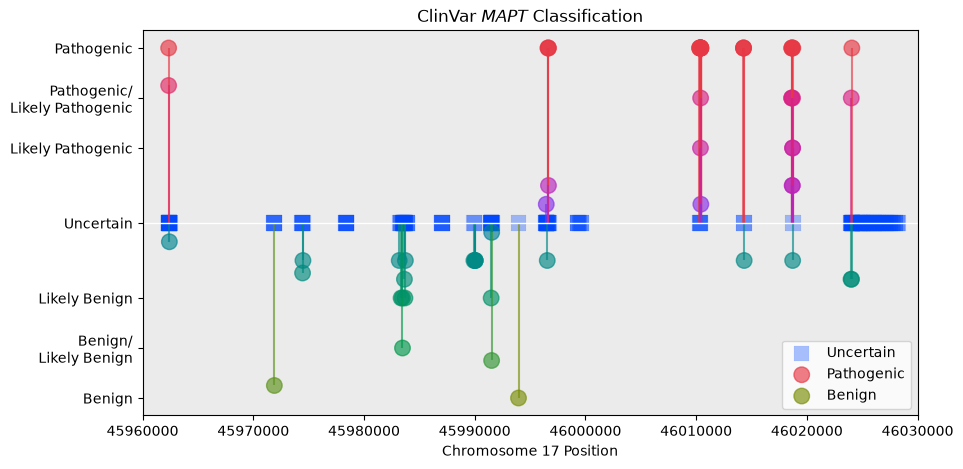

In [5]:
# COMPARING CLINVAR SIGNIFICANCE to POSITION
# (1.c) Create stem plot (matplotlib) of significance based on chromosomal position

cmap = {
    7.0: "#E63845A6", #last 2 sets the alpha value
    5.5: "#E12A66A6",
    5.0: "#D82285A6",
    3.0: "#CA20A2A6",
    1.5: "#B824BDA6",
    0.75: "#872FEAA6",
    0: "#0047FF55",
    -7.0: "#7A8E06A6",
    -6.5: "#5E921CA6",
    -5.5: "#329633A6",
    -5.0: "#00984BA6",
    -4.5: "#008E78A6",
    -3.0: "#009268A6",
    -2.25: "#008E79A6",
    -2: "#008B7FA6",
    -1.5: "#008985A6",
    -0.75: "#008490A6", 
    -0.375: "#007F9AA6"
}


fig, ax = plt.subplots(figsize=(10,5))


if uniq_uncertain:
    # make xy tuple for stem plot
    x_un, y_un = zip(*uniq_uncertain) 
    c_un = [cmap.get(k) for k in y_un]
    l_un, s_un, ooo = ax.stem(
        x_un,
        y_un,
        basefmt=' ',
    )
    s_un.set_colors(c_un)
    l_un.set_visible(False)
    ax.scatter(x_un, y_un, color=c_un, marker='s', label='Uncertain', s=125, linewidths=0.1)

if uniq_path:
    # make xy tuple for stem plot
    x_path, y_path = zip(*uniq_path)
    c_path = [cmap.get(i) for i in y_path]
    l_path, s_path, o =ax.stem(
        x_path,
        y_path,
        basefmt=' ',
    )
    s_path.set_colors(c_path)
    l_path.set_visible(False)
    ax.scatter(x_path, y_path, color=c_path, label='Pathogenic', s=125)


if uniq_ben:
    # make xy tuple for stem plot
    x_ben, y_ben = zip(*uniq_ben)
    c_ben = [cmap.get(j) for j in y_ben]
    l_ben, s_ben, oo = ax.stem(
        x_ben,
        y_ben,
        basefmt=' ',
    )
    s_ben.set_colors(c_ben)
    l_ben.set_visible(False)
    ax.scatter(x_ben, y_ben, color=c_ben, label='Benign', s=125)



ax.axhline(0, color="white", linewidth=1)
ax.legend(loc='lower right')
ax.set_xlim(45960000,46030000)
ax.set_facecolor("#EBEBEB")
ax.ticklabel_format(style='plain', axis='x', useOffset=True)
ax.set_yticks([7, 5, 3, 0, -3, -5, -7], 
              labels=['Pathogenic', 'Pathogenic/\nLikely Pathogenic', 'Likely Pathogenic', 'Uncertain', 
                      'Likely Benign', 'Benign/\nLikely Benign', 'Benign'])
ax.set_xlabel('Chromosome 17 Position')
ax.set_title('ClinVar $MAPT$ Classification')

plt.show()


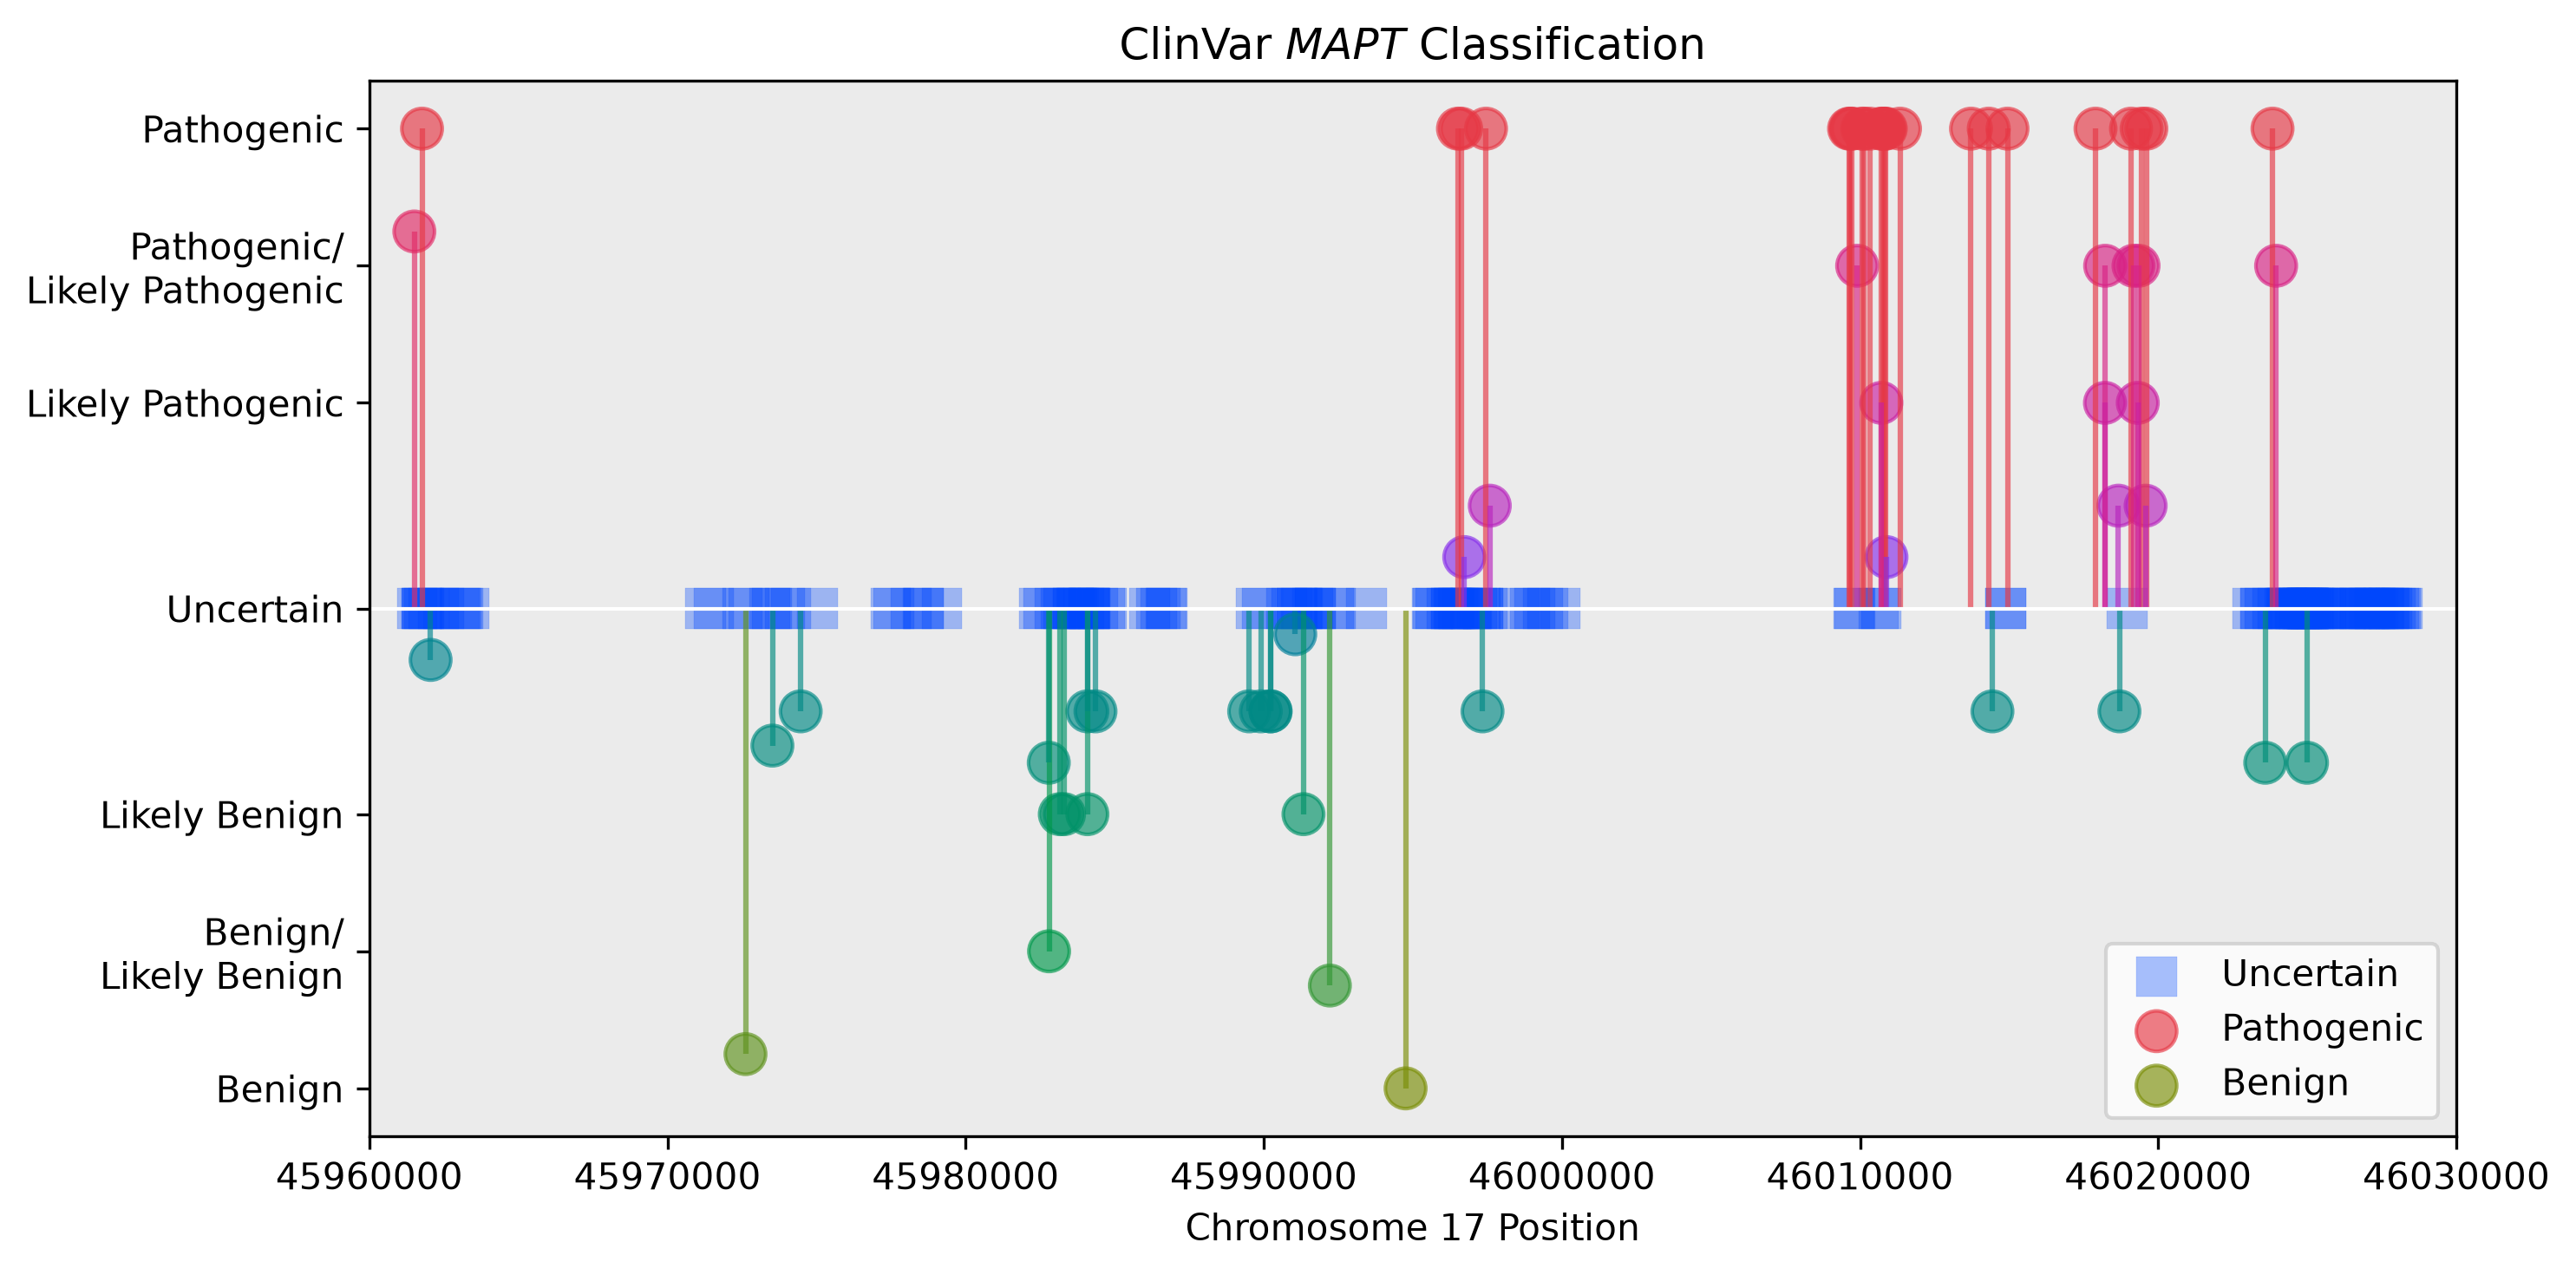

In [6]:
# COMPARING CLINVAR SIGNIFICANCE to POSITION
# (1.d) Create stem plot (matplotlib) of significance based on chromosomal position
# but add jitter to make stems more visible 

cmap = {
    7.0: "#E63845A6", #last 2 sets the alpha value
    5.5: "#E12A66A6",
    5.0: "#D82285A6",
    3.0: "#CA20A2A6",
    1.5: "#B824BDA6",
    0.75: "#872FEAA6",
    0: "#0047FF55",
    -7.0: "#7A8E06A6",
    -6.5: "#5E921CA6",
    -5.5: "#329633A6",
    -5.0: "#00984BA6",
    -4.5: "#008E78A6",
    -3.0: "#009268A6",
    -2.25: "#008E79A6",
    -2: "#008B7FA6",
    -1.5: "#008985A6",
    -0.75: "#008490A6", 
    -0.375: "#007F9AA6"
}

# set seed for np.random
np.random.seed(100)

# create jitter


fig, ax = plt.subplots(figsize=(10,5), dpi=300, tight_layout=False)


if uniq_uncertain:
    # make xy tuple for stem plot
    x_un, y_un = zip(*uniq_uncertain)
    x_un_noise = np.random.uniform(-1000,1000, len(uniq_uncertain))
    x_un_jitter = x_un + x_un_noise 
    c_un = [cmap.get(k) for k in y_un]
    l_un, s_un, ooo = ax.stem(
        x_un_jitter,
        y_un,
        basefmt=' ',
    )
    s_un.set_colors(c_un)
    l_un.set_visible(False)
    ax.scatter(x_un_jitter, y_un, color=c_un, marker='s', label='Uncertain', s=125, linewidths=0.1)

if uniq_path:
    # make xy tuple for stem plot
    x_path, y_path = zip(*uniq_path)
    x_path_noise = np.random.uniform(-1000,1000, len(uniq_path))
    x_path_jitter = x_path + x_path_noise 
    c_path = [cmap.get(i) for i in y_path]
    l_path, s_path, o =ax.stem(
        x_path_jitter,
        y_path,
        basefmt=' ',
    )
    s_path.set_colors(c_path)
    l_path.set_visible(False)
    ax.scatter(x_path_jitter, y_path, color=c_path, label='Pathogenic', s=125)


if uniq_ben:
    # make xy tuple for stem plot
    x_ben, y_ben = zip(*uniq_ben)
    x_ben_noise = np.random.uniform(-1000,1000, len(uniq_ben))
    x_ben_jitter = x_ben + x_ben_noise 
    c_ben = [cmap.get(j) for j in y_ben]
    l_ben, s_ben, oo = ax.stem(
        x_ben_jitter,
        y_ben,
        basefmt=' ',
    )
    s_ben.set_colors(c_ben)
    l_ben.set_visible(False)
    ax.scatter(x_ben_jitter, y_ben, color=c_ben, label='Benign', s=125)



ax.axhline(0, color="white", linewidth=1)
ax.legend(loc='lower right')
ax.set_xlim(45960000,46030000)
ax.set_facecolor("#EBEBEB")
ax.ticklabel_format(style='plain', axis='x', useOffset=True)
ax.set_yticks([7, 5, 3, 0, -3, -5, -7], 
              labels=['Pathogenic', 'Pathogenic/\nLikely Pathogenic', 'Likely Pathogenic', 'Uncertain', 
                      'Likely Benign', 'Benign/\nLikely Benign', 'Benign'])
ax.set_xlabel('Chromosome 17 Position')
ax.set_title('ClinVar $MAPT$ Classification')

plt.show()



### 2. Comparing Amino Acid Mutations

(a) Use `pandas` dataframe function `iloc[]` to extract columns of the amino acid mutations and their position relative to the full protein sequence

- Then, create an index for each amino acid, and use the index to extract all rows that match the desired amino acid

- Extract minimum and maximum values from the dataframe subset for establishing the limits of the heatmap
</br>

(b) Get the wildtype sequence for the protein (TAU) from a UniProt FASTA file, and create a dict of the Kyte-Doolittle hydrophobicity scale for the Y-axis of the heatmap
</br>

(c) Create and use a helper function to determine the count of mutated amino acids, for each amino acid type, based on their position compared to the wildtype sequence
</br>

(d) Convert a merged list of all outputs of helper function into an array, ready for use in the final heatmap plot

- Use `matplotlib` to create a heatmap plot using `pcolormesh` 

In [7]:
# COMPARING AMINO ACID MUTATIONS
# 2(a) extract mutant amino acids from dataframe, and count repeats
aa_mutation = df.iloc[:,[17, 18]].dropna().replace(r'[^/]+/([^/]+)',r'\1', regex=True) # get rid of NaN entries
# also keep only mutation in Amino_acids (e.g. G/R -> R)

aa_mut_pos = aa_mutation.groupby('Amino_acids')['Protein_position'].apply(list).to_dict()
# using pandas to group Amino_acids and Protein_position, to list then dict

aminoacids= ['A','R','N','D','C','Q',
            'E','G','H','I','L','K','M',
            'F','P','S','T','W','Y','V'
            ]
# create index of amino acids

aA,aR, aN, aD, aC, aQ, aE, aG, aH, aI, aL, aK, aM, aF, aP, aS, aT, aW, aY, aV = [
    aa_mut_pos.get(aIdx, []) for aIdx in aminoacids
    ]

count_out= aa_mutation.value_counts().reset_index() #find how many times amino acid changes occur at each protein position

ct_min = count_out.iloc[:,[2]].min().to_string(header=False,index=False)
ct_max=count_out.iloc[:,[2]].max().to_string(header=False,index=False)
# get min and max values for later use in heatmap


In [8]:
# COMPARING AMINO ACID MUTATIONS
# 2(b) use hydrophobicity scale for later use in y axis of heatmap, and get the wildtype
# amino acid sequence for TAU to compare the amino acid mutations to
#
# get amino acid hydropathicity scale (Kyte-Doolittle)
# link: https://web.expasy.org/protscale/pscale/Hydropath.Doolittle.html

hydrophobicity= { 'A':1.800, 'R':-4.500, 'N':-3.500,
                'D':-3.500, 'C':2.500, 'Q':-3.500, 'E':-3.500, 'G':-0.400,
                'H':-3.200, 'I':4.500, 'L':3.800, 'K':-3.900, 'M':1.900,
                'F':2.800, 'P':-1.600, 'S':-0.800, 'T':-0.700, 'W':-0.900,
                'Y':-1.300, 'V':4.200  
            }

# sort hydrophobicity for graph
sorted_hydro=sorted(hydrophobicity.items(), key=lambda item: item[1])

# get amino acids sorted by hydrophobicity
aas_hydro = [x[0] for x in sorted_hydro]

# print(aas_hydro)

# get amino acid sequence for full MAPT gene protein (TAU)
# link: https://rest.uniprot.org/uniprotkb/P10636.fasta

tau_fasta = open('uniprotkb_tau.fasta', 'r')

seqlist=[]

for line in tau_fasta:
    if line.startswith('>'):
        continue
    else:
        line=line.strip('\n')
        seqlist.append(line)

tau_seq="".join(seqlist) # to join the string together


tau_pos=[]
ind = 1

for A in tau_seq:
    tau_pos.append([A, ind])
    ind += 1

pos_length =len(tau_pos)

# print(pos_length)


In [9]:
# COMPARING AMINO ACID MUTATIONS
# 2(c) make helper function for extracting individual amino acid counts compared
# to the wildtype list to get their position
#
# create helper function to extract amino acids
def aa_positions(aa: list, pos_length: int) -> list[list[int]]:
    countAA= Counter(aa)
    outAA=[]

    for i in range(1, pos_length + 1):
        outAA.append([i, countAA[str(i)]])

    return outAA

In [10]:
# use helper function
# extract each amino acid + position list

Alist= aa_positions(aA, pos_length)
Rlist= aa_positions(aR, pos_length)
Nlist= aa_positions(aN, pos_length)
Dlist= aa_positions(aD, pos_length)
Clist= aa_positions(aC, pos_length)
Qlist= aa_positions(aQ, pos_length)
Elist= aa_positions(aE, pos_length)
Glist= aa_positions(aG, pos_length)
Hlist= aa_positions(aH, pos_length)
Ilist= aa_positions(aI, pos_length)
Llist= aa_positions(aL, pos_length)
Klist= aa_positions(aK, pos_length)
Mlist= aa_positions(aM, pos_length)
Flist= aa_positions(aF, pos_length)
Plist= aa_positions(aP, pos_length)
Slist= aa_positions(aS, pos_length)
Tlist= aa_positions(aT, pos_length)
Wlist= aa_positions(aW, pos_length)
Ylist= aa_positions(aY, pos_length)
Vlist= aa_positions(aV, pos_length)

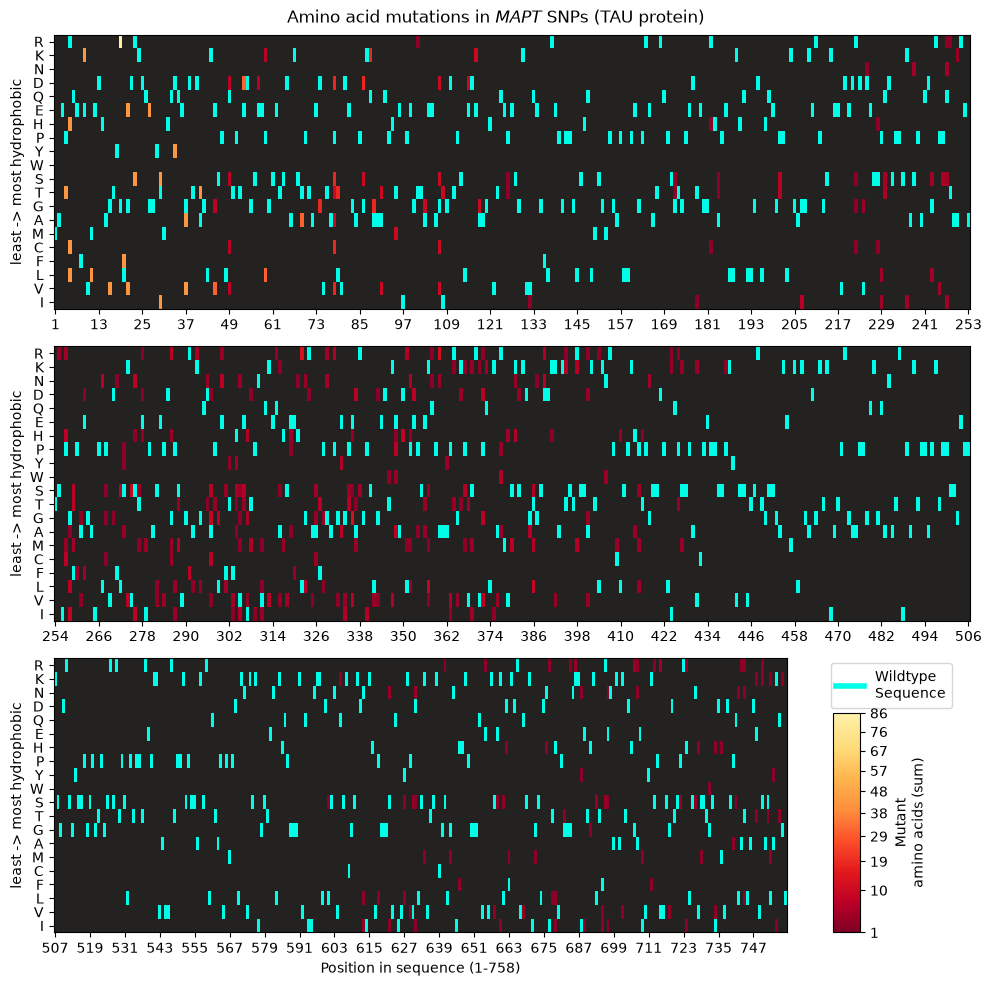

In [11]:
# COMPARING AMINO ACID MUTATIONS
# 2(d) create a merged list from all of the outputs of the helper function,
# then convert to an array for plotting, and finally plot to heatmap
# using matplotlib
# 
# create lists of each amino acid type with occurence counts at each position in the full protein
aa_list= [Rlist, Klist, Nlist, Dlist, Qlist, Elist, Hlist, Plist, Ylist,
          Wlist, Slist, Tlist, Glist, Alist, Mlist, Clist, Flist, Llist, Vlist, Ilist
          ]

# convert to array for plotting
aa_comp= np.array([[i[1] for i in xlist] for xlist in aa_list], dtype=float)

# create array of the canonical tau sequence for plotting
tau_seq_mask = np.array([[aa == ind for ind in tau_seq] for aa in aas_hydro])

# create sections for wrapping plot to 3 lines
n_tracks = 3
aas_sect=np.array_split(aa_comp, n_tracks, axis=1)
mask_sect=np.array_split(tau_seq_mask, n_tracks, axis=1)
pos_sect=np.array_split(tau_pos, n_tracks)

# create legend box for the wildtype sequence markers
wt_legend = [Line2D([0],[0], color="#00FDE8", lw=4, label='Wildtype\nSequence')]

# matplotlib figure setup
fig, axes = plt.subplots(n_tracks, 1, figsize=(10,10))

fig.suptitle('Amino acid mutations in $MAPT$ SNPs (TAU protein)')

# set minimum and maximum values for heatmap
vmin=int(ct_min)
vmax=int(ct_max)

# set separate color for wildtype tau sequence markers
cval=ListedColormap(["#00FDE8"])

# adjust yellow-orange-red colormap for better visibility in heatmap
newcmp=plt.get_cmap('YlOrRd_r', 256)
newcolors=newcmp(np.linspace(0,0.9,256))
newcolors[0,:] = [1.0, 1.0, 1.0, 0.0]
adjcmap=LinearSegmentedColormap.from_list('truncated_YlOrRd_r', newcolors)

# plotting each layer of the heatmap
# including the wildtype sequence (tau_mask) and mutants (mesh)
for ax, aas_sect, mask_sect, pos_sect in zip(axes, aas_sect, mask_sect, pos_sect):
    mesh = ax.pcolormesh(aas_sect, cmap=adjcmap, 
                norm=colors.PowerNorm(gamma=0.75, vmin=vmin, vmax=vmax),
                edgecolors='none', linewidth=1,
                antialiased=False) # PowerNorm adjusts the colormap to be more condensed at the upper end of heatmap

    tau_mask = np.where(mask_sect, 1.0, np.nan)
    ax.pcolormesh(tau_mask, cmap=cval, edgecolors='none',
                   antialiased=False)

    ax.invert_yaxis()
    ax.margins(0)

    # set labels on y axis
    ax.set_yticks(np.arange(len(aas_hydro))+0.5, labels=aas_hydro) 

    # setup ticks on x axis, using steps to show increments instead of full 758 individual ticks
    step = max(1, len(pos_sect) //20)
    tick_lbl=[p[1] for p in pos_sect[::step]]
    tick_pos=np.arange(0, len(pos_sect), step) + 0.5
    ax.set_xticks(tick_pos, labels=tick_lbl, rotation=0, fontsize=10)
    ax.set_facecolor("#242121")
    ax.set_ylabel('least -> most hydrophobic')

# set labels on colorbar
cbticks=np.linspace(vmin, vmax, 10)

# create colorbar
cb = fig.colorbar(
    mesh, ticks=cbticks, format='%d',
    label='Mutant\namino acids (sum)',
    anchor=(0,0), 
    shrink=0.8, aspect=20*0.4
    )


cb.ax.tick_params(labelsize=10)

# create legend
ax.legend(handles=wt_legend, bbox_to_anchor=(1.05,0.9), loc='center left')
ax.set_xlabel('Position in sequence (1-758)')


plt.tight_layout(pad=1)
plt.show()
